In [9]:

from google.colab import files
import pandas as pd

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(
    filename,
    sep="\t",
    header=None,
    names=["label", "message"]
)

print(df.head())
print("Total messages:", len(df))
print(df["label"].value_counts())

Saving SMSSpamCollection to SMSSpamCollection (3)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Total messages: 5572
label
ham     4825
spam     747
Name: count, dtype: int64


Accuracy: 96.05 %
Precision: 100.0 %
Recall: 70.47 %
F1-score: 82.68 %

Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.96      1.00      0.98       966
        Spam       1.00      0.70      0.83       149

    accuracy                           0.96      1115
   macro avg       0.98      0.85      0.90      1115
weighted avg       0.96      0.96      0.96      1115



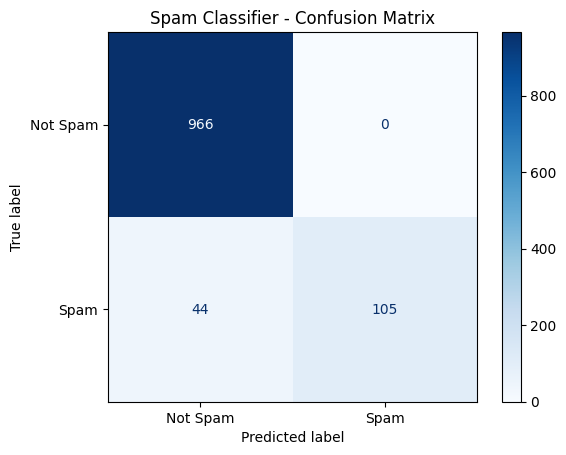

Model saved as spam_classifier.pkl


In [10]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import joblib

# Prepare the messages and labels
X = df["message"].astype(str)
y = df["label"].str.strip().str.lower().map(
    {"ham": 0, "spam": 1}
)

# Remove any invalid rows
valid = y.notna()
X = X[valid]
y = y[valid].astype(int)

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create the machine-learning pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", MultinomialNB())
])

# Train the model
model.fit(X_train, y_train)

# Evaluate the model
predictions = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, predictions) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, predictions) * 100, 2), "%")
print("Recall:", round(recall_score(y_test, predictions) * 100, 2), "%")
print("F1-score:", round(f1_score(y_test, predictions) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test, predictions, target_names=["Not Spam", "Spam"]
))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions,
    display_labels=["Not Spam", "Spam"],
    cmap="Blues"
)
plt.title("Spam Classifier - Confusion Matrix")
plt.show()

# Save the trained model
joblib.dump(model, "spam_classifier.pkl")
print("Model saved as spam_classifier.pkl")

In [11]:

messages = [
    "Congratulations! You won a free prize!",
    "Hey, are we meeting at 5 PM?",
    "Claim your cash reward now!",
    "Please call me when you are free.",
    "You have won a lottery. Click here!",
    "Your class starts at 9 AM tomorrow.",
    "Get a special offer today!",
    "Can you send me your notes?",
    "Urgent! Claim your free gift now!",
    "Happy birthday! Have a wonderful day."
]

for msg in messages:
    prediction = model.predict([msg])[0]
    label = "SPAM" if prediction == 1 else "NOT SPAM"
    probabilities = model.predict_proba([msg])[0]
    confidence = max(probabilities) * 100

    print("Message:", msg)
    print("Prediction:", label)
    print(f"Model confidence: {confidence:.2f}%")
    print("-" * 40)

Message: Congratulations! You won a free prize!
Prediction: SPAM
Model confidence: 83.86%
----------------------------------------
Message: Hey, are we meeting at 5 PM?
Prediction: NOT SPAM
Model confidence: 99.39%
----------------------------------------
Message: Claim your cash reward now!
Prediction: SPAM
Model confidence: 82.32%
----------------------------------------
Message: Please call me when you are free.
Prediction: NOT SPAM
Model confidence: 97.91%
----------------------------------------
Message: You have won a lottery. Click here!
Prediction: NOT SPAM
Model confidence: 87.59%
----------------------------------------
Message: Your class starts at 9 AM tomorrow.
Prediction: NOT SPAM
Model confidence: 99.05%
----------------------------------------
Message: Get a special offer today!
Prediction: NOT SPAM
Model confidence: 87.97%
----------------------------------------
Message: Can you send me your notes?
Prediction: NOT SPAM
Model confidence: 97.14%
------------------------

In [12]:

from google.colab import files

files.download("spam_classifier.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

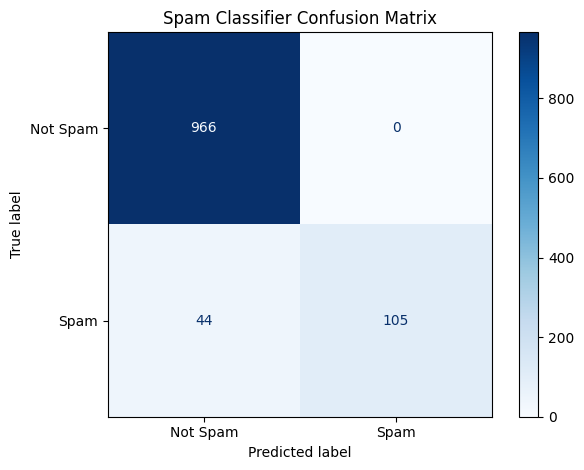

In [13]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    labels=[0, 1],
    display_labels=["Not Spam", "Spam"],
    cmap="Blues"
)

plt.title("Spam Classifier Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

In [14]:

from google.colab import files
files.download("confusion_matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>